In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("air_quality_dataset.csv")

In [4]:
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:\n", df.describe())

        PM2.5        PM10         NOx        NO2        SO2        VOCs  \
0   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261   
1  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987   
2   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338   
3   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319   
4   78.265276  113.977926  105.644340  59.202337  17.696806  181.713667   

         CO         CO2       CH4  Temperature  
0  2.789606  427.674347  1.706105    31.085120  
1  1.966569  529.739619  2.492663    33.711103  
2  2.626446  499.889443  2.431165    33.778698  
3  1.779360  388.283712  1.818563    31.565877  
4  3.240533  464.739197  2.597225    32.229835  

Dataset shape: (500, 10)

Columns: ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']

Data types:
 PM2.5          float64
PM10           float64
NOx            float64
NO2            float64
SO2            float64
VOCs    

In [5]:
target = "PM2.5"
features = [c for c in df.columns if c != target]

data = df[features + [target]].dropna()
X = data[features]
y = data[target]

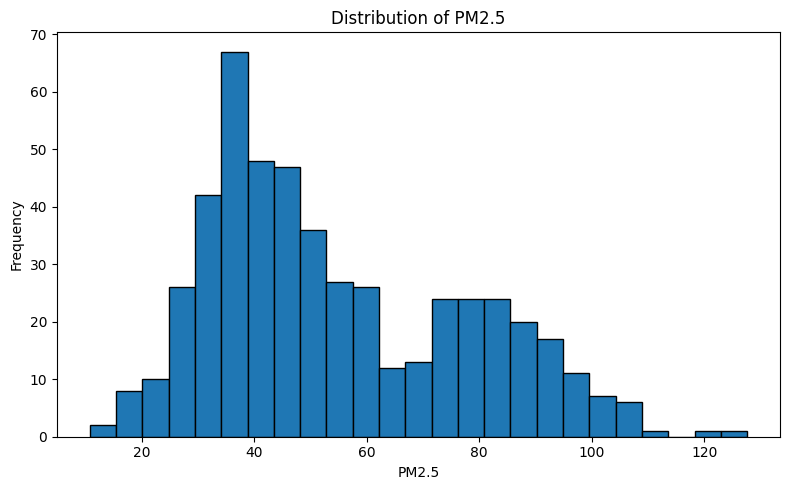

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(y, bins=25, edgecolor="black")
plt.xlabel("PM2.5")
plt.ylabel("Frequency")
plt.title("Distribution of PM2.5")
plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 400
Testing records: 100


In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [9]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Actual PM2.5": y_test.values,
    "Predicted PM2.5": y_pred
})
print("\nACTUAL VS PREDICTED (first 10 rows)")
print(results.head(10).to_string(index=False))


ACTUAL VS PREDICTED (first 10 rows)
 Actual PM2.5  Predicted PM2.5
    26.548982        40.991027
    35.961208        37.135632
    34.236104        34.256109
    84.233115        73.898407
    57.061711        44.523695
    43.500793        43.268909
    16.124681        36.976914
    43.770788        37.294684
    76.624911        82.264247
    55.669846        44.765556


In [12]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2-score: {r2:.4f}")


MODEL EVALUATION
MAE: 11.0417
MSE: 212.6710
RMSE: 14.5832
R2-score: 0.6245


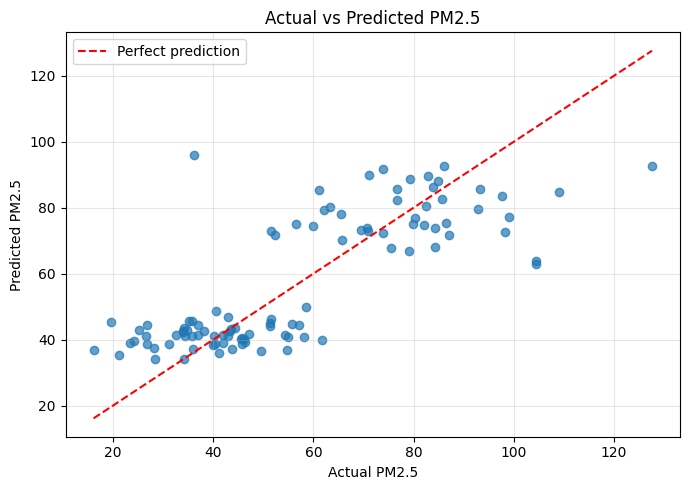

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted PM2.5")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
print("\nFEATURE COEFFICIENTS")
print(coefficients.to_string(index=False))



FEATURE COEFFICIENTS
    Feature  Coefficient
        CH4     6.962981
        SO2     0.922777
         CO    -0.704658
Temperature    -0.253045
        CO2     0.159350
       PM10     0.085760
        NO2     0.056628
       VOCs     0.050416
        NOx    -0.043637


In [15]:
sample = X_test.iloc[[0]]
print("\nExample input record:\n", sample)
print("Predicted PM2.5:", round(model.predict(sample)[0], 4))

# 12. Save output
results.to_csv("linear_regression_pm25_predictions.csv", index=False)
print("\nSaved: linear_regression_pm25_predictions.csv")

print("\nCONCLUSION")
print(
    "Linear Regression was used to predict the continuous PM2.5 value from "
    "the other air-quality measurements. Review the test MAE, RMSE and R-squared "
    "to judge how well the model performs on unseen records."
)



Example input record:
           PM10        NOx        NO2       SO2       VOCs        CO  \
361  67.391718  25.540563  15.565702  7.273767  49.813578  1.344661   

            CO2       CH4  Temperature  
361  386.943809  2.126732    25.905401  
Predicted PM2.5: 40.991

Saved: linear_regression_pm25_predictions.csv

CONCLUSION
Linear Regression was used to predict the continuous PM2.5 value from the other air-quality measurements. Review the test MAE, RMSE and R-squared to judge how well the model performs on unseen records.
